In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller, kpss

In [6]:
#========================================================
# CHARGEMENT DES DONNEES
#========================================================
data = pd.read_csv("API_NY.GDP.MKTP.KD.ZG_DS2_fr_csv_v2_122.csv", skiprows = 4)
data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,3.493430,3.212471,1.229144,-23.940059,14.833692,10.607961,9.516360,6.810777,NaN,NaN
1,NaN,AFE,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,0.418605,7.937089,5.624317,4.650349,5.138153,...,2.678863,2.706207,1.935593,-2.930764,4.452643,3.668029,1.941382,2.787931,3.743016,NaN
2,Afghanistan,AFG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,2.647003,1.189228,3.911603,-2.351101,-20.738839,-6.240172,2.266944,1.873193,NaN,NaN
3,NaN,AFW,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1.869593,3.726016,7.038172,5.364580,4.105660,...,2.302761,2.899954,3.283142,-3.718793,2.545473,4.477108,3.644591,4.596183,4.600100,NaN
4,Angola,AGO,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.164689,-0.506698,-1.055234,-5.273491,1.090584,3.557492,1.320166,4.952679,3.133535,NaN


In [10]:
#++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
#TRANSFORMATION DU DATASET AU FORMAT LONG (RAMENER LES VARIABLES ANNEES A LA VERTICALE)
#++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Identification des colonnes annnées
col_year = [ col for col in data.columns if col.strip().isdigit()]
col_id = [col for col in data.columns if col not in col_year]
# Reshape au format long
data_long = data.melt(
    id_vars = col_id,
    value_vars = col_year,
    var_name = "Year",
    value_name = "Croissance_PIB",
    
)
data_long.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Unnamed: 70,Year,Croissance_PIB
0,Aruba,ABW,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1960,NaN
1,NaN,AFE,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1960,NaN
2,Afghanistan,AFG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1960,NaN
3,NaN,AFW,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1960,NaN
4,Angola,AGO,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1960,NaN


In [19]:
# typage des colonnes crées
data_long["year"] = data_long["Year"].astype(int)
data_long["Croissance_PIB"] = pd.to_numeric(
    data_long["Croissance_PIB"], errors="coerce"
)
print(data_long["year"].dtype)
print(data_long["Croissance_PIB"].dtype)

int64
float64


In [27]:
# Extraction des données du Congo 
data_cog  = (data_long[data_long["Country Code"] == "COG"].sort_values("Year").reset_index(drop=True).copy())
data_cog.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Unnamed: 70,Year,Croissance_PIB,year
0,"Congo, République du",COG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1960,NaN,1960
1,"Congo, République du",COG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1961,8.350727,1961
2,"Congo, République du",COG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1962,5.202309,1962
3,"Congo, République du",COG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1963,-4.029300,1963
4,"Congo, République du",COG,Croissance du PIB (% annuel),NY.GDP.MKTP.KD.ZG,NaN,1964,3.816796,1964


In [26]:
#Verification des valeurs manquantes et doublons
print(data_cog.isnull().sum())
print(f" Nombre de doublons: {data_cog.duplicated().sum()}")

Country Name       0
Country Code       0
Indicator Name     0
Indicator Code     0
Unnamed: 70       66
Year               0
Croissance_PIB     1
year               0
dtype: int64
 Nombre de doublons: 0


In [37]:
#Imputation de la valeur manquante par la moyenne
data_cog["Croissance_PIB"] = data_cog["Croissance_PIB"].fillna(data_cog["Croissance_PIB"].mean())
data_cog.isnull().sum()
# sauvegarde du dataset extrait congo
data_cog.to_csv("data_cog.csv")

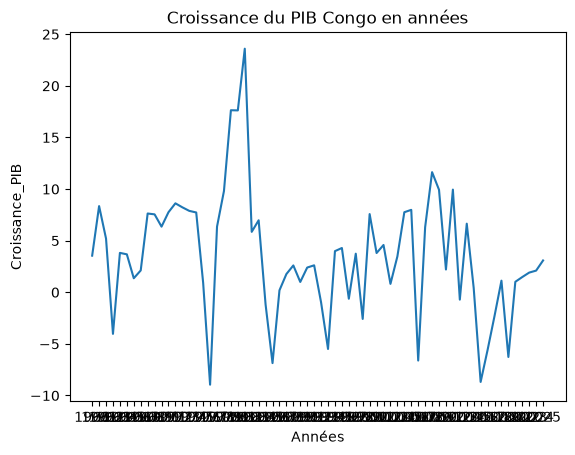

In [43]:
# Verification de la statiionnarité visuellement
x = data_cog["Year"]
Y = data_cog["Croissance_PIB"]

plt.plot(x,Y)
plt.xlabel("Années")
plt.ylabel("Croissance_PIB")
plt.title('Croissance du PIB Congo en années')
plt.show()

In [44]:
#Test de stationnarité avec par ADF 
adf_stat, adf_p, _, _, crit_adf, _ = adfuller(Y, autolag="AIC")

print("Test ADF\n (H0 : non stationnaire / racine unitaire) \n (H1 : stationnaire / inexistence de la racine unitaire) ")
print(f"Statistique : {adf_stat:.4f} | p-value : {adf_p:.4f}")
print("Seuils critiques :", crit_adf)

Test ADF
 (H0 : non stationnaire / racine unitaire) 
 (H1 : stationnaire / inexistence de la racine unitaire) 
Statistique : -4.8327 | p-value : 0.0000
Seuils critiques : {'1%': np.float64(-3.5352168748293127), '5%': np.float64(-2.9071540828402367), '10%': np.float64(-2.5911025443786984)}


C:\Users\GIVMMBD\AppData\Local\Temp\ipykernel_8476\2802548339.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, crit_adf, _ = adfuller(Y, autolag="AIC")


In [ ]:
# la p-value=0.00000 siginficative au seuil de 5% et autres donc HO est rejettée la variable croissance_PIB est stationnaire.

In [40]:
# Creation des retrads 
MAX_LAG = 3
for lag in range(1, MAX_LAG + 1):
  data_cog[f"lag_{lag}"] = data_cog["Croissance_PIB"].shift(lag)

# Conserver les lignes où les lags nécessaires sont disponibles
cols_lags = [f"lag_{i}" for i in range(1, MAX_LAG + 1)]
df_ml = data_cog.dropna(subset=cols_lags + ["Croissance_PIB"]).reset_index(
    drop=True
)

X = df_ml[cols_lags]
y = df_ml["Croissance_PIB"]

print(
    f"Jeu ML prêt : {len(df_ml)} lignes (années {df_ml['Year'].min()} à"
    f" {df_ml['Year'].max()})"
)
print("Variables explicatives :", cols_lags)

Jeu ML prêt : 63 lignes (années 1963 à 2025)
Variables explicatives : ['lag_1', 'lag_2', 'lag_3']


In [41]:
# 3. Définition des pipelines ML
pipelines = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0)),
    ]),
    "ElasticNet": Pipeline([
        ("scaler", StandardScaler()),
        ("model", ElasticNet(alpha=0.5, l1_ratio=0.5, random_state=42, max_iter=5000)),
    ]),
    "RandomForest": Pipeline([
        ("model", RandomForestRegressor(n_estimators=200, max_depth=3, random_state=42)),
    ]),
}

In [42]:
# 4. Validation croisée temporelle (TimeSeriesSplit)
tscv = TimeSeriesSplit(n_splits=5)

for nom, pipe in pipelines.items():
  mae_scores, rmse_scores = [], []
  for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mae_scores.append(mean_absolute_error(y_test, y_pred))
    rmse_scores.append(root_mean_squared_error(y_test, y_pred))

  print(
      f"{nom:13s} -> MAE moyen : {np.mean(mae_scores):.3f} | RMSE moyen :"
      f" {np.mean(rmse_scores):.3f}"
  )

Ridge         -> MAE moyen : 5.115 | RMSE moyen : 6.234
ElasticNet    -> MAE moyen : 5.204 | RMSE moyen : 6.228
RandomForest  -> MAE moyen : 5.617 | RMSE moyen : 6.634


In [45]:
import joblib
# Définition de l'année cible finale et du pipeline retenu
prev_horizon = 2030
last_year_prev = int(df_ml["Year"].max())
HORIZON = max(0, prev_horizon - last_year_prev)

print(f"Dernière année historique : {last_year_prev}")
print(f"Horizon jusqu'en {prev_horizon} : {HORIZON} année(s)")

modele_ar = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0)),
])

# Entraînement final sur l'ensemble des observations (X, y)
modele_ar.fit(X, y)

# Prévision récursive année par année jusqu'à 2030
historique = list(y.values)
previsions = []

for step in range(1, HORIZON + 1):
  annee_future = last_year_prev + step
  ligne_x = {f"lag_{k}": historique[-k] for k in range(1, MAX_LAG + 1)}
  X_futur = pd.DataFrame([ligne_x])[cols_lags]

  pred_croissance = float(modele_ar.predict(X_futur)[0])
  previsions.append({
      "Year": annee_future,
      "Croissance_PIB_Predite": round(pred_croissance, 3),
  })
  historique.append(pred_croissance)

df_prev_2030 = pd.DataFrame(previsions)
print("\nPrévisions autorégressives de la croissance du PIB réel jusqu'en 2030 :")
print(df_prev_2030.to_string(index=False))

# sauvegarde du pipeline entraîné avec joblib
joblib.dump(modele_ar, "pipeline_ar_pib_congo.joblib")

Dernière année historique : 2025
Horizon jusqu'en 2030 : 5 année(s)

Prévisions autorégressives de la croissance du PIB réel jusqu'en 2030 :
 Year  Croissance_PIB_Predite
 2026                   3.246
 2027                   3.384
 2028                   3.404
 2029                   3.416
 2030                   3.416


['pipeline_ar_pib_congo.joblib']

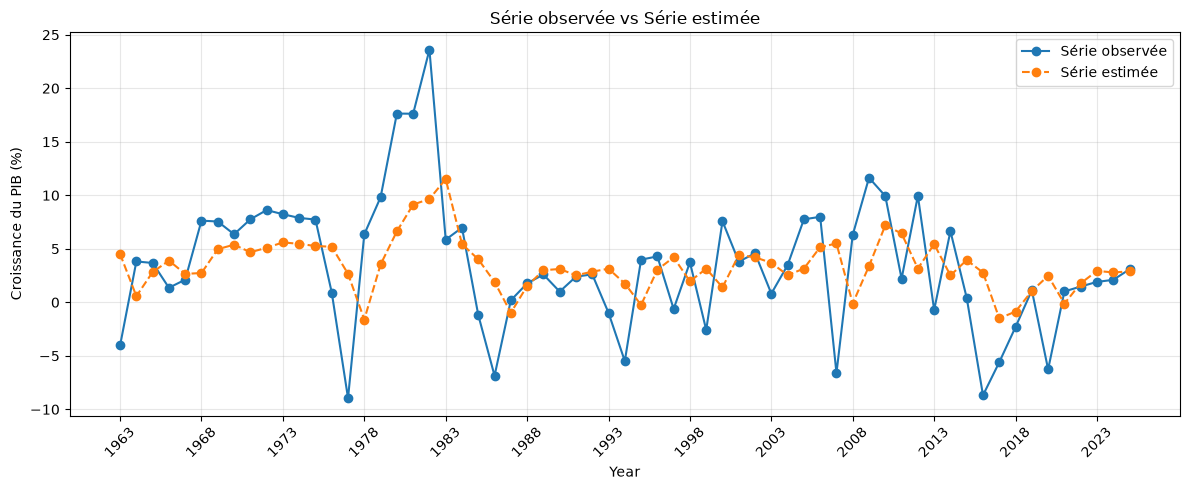

In [51]:
# Visualisation de la serie observée et la serie estimée
import matplotlib.pyplot as plt

annees = df_ml["Year"].astype(int)

plt.figure(figsize=(12, 5))
plt.plot(annees, df_ml["Croissance_PIB"], marker="o", label="Série observée")
plt.plot(
    annees,
    modele_ar.predict(X),
    marker="o",
    linestyle="--",
    label="Série estimée",
)

plt.xticks(range(annees.min(), annees.max() + 1, 5), rotation=45)
plt.title("Série observée vs Série estimée")
plt.xlabel("Year")
plt.ylabel("Croissance du PIB (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
# Reajustement du modele AR
df_base = data_cog.sort_values("Year").reset_index(drop=True).copy()

# Évaluation d'une baseline naïve (prévision = lag_1) sur 5 folds
df_lag1 = df_base.copy()
df_lag1["lag_1"] = df_lag1["Croissance_PIB"].shift(1)
df_lag1 = df_lag1.dropna(subset=["lag_1", "Croissance_PIB"]).reset_index(
    drop=True
)

tscv = TimeSeriesSplit(n_splits=5)
base_mae, base_rmse = [], []

for train_idx, test_idx in tscv.split(df_lag1):
  y_test_b = df_lag1["Croissance_PIB"].iloc[test_idx]
  y_pred_b = df_lag1["lag_1"].iloc[test_idx]
  base_mae.append(mean_absolute_error(y_test_b, y_pred_b))
  base_rmse.append(root_mean_squared_error(y_test_b, y_pred_b))

print(
    f"Baseline naive (lag_1) -> MAE moyen : {np.mean(base_mae):.3f} | RMSE"
    f" moyen : {np.mean(base_rmse):.3f}\n"
)

# Grille légère d'ajustement : MAX_LAG et alpha de Ridge
resultats = []

for max_lag in [1, 2, 3, 4]:
  df_tmp = df_base.copy()
  cols = [f"lag_{k}" for k in range(1, max_lag + 1)]
  for k in range(1, max_lag + 1):
    df_tmp[f"lag_{k}"] = df_tmp["Croissance_PIB"].shift(k)
  df_tmp = df_tmp.dropna(subset=cols + ["Croissance_PIB"]).reset_index(
      drop=True
  )

  X_tmp = df_tmp[cols]
  y_tmp = df_tmp["Croissance_PIB"]
  tscv_tmp = TimeSeriesSplit(n_splits=5)

  for alpha in [1.0, 5.0, 10.0, 25.0, 50.0]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])
    maes, rmses = [], []
    for train_idx, test_idx in tscv_tmp.split(X_tmp):
      pipe.fit(X_tmp.iloc[train_idx], y_tmp.iloc[train_idx])
      preds = pipe.predict(X_tmp.iloc[test_idx])
      maes.append(mean_absolute_error(y_tmp.iloc[test_idx], preds))
      rmses.append(root_mean_squared_error(y_tmp.iloc[test_idx], preds))

    resultats.append({
        "MAX_LAG": max_lag,
        "alpha": alpha,
        "MAE_moyen": round(float(np.mean(maes)), 3),
        "RMSE_moyen": round(float(np.mean(rmses)), 3),
    })

df_grid = pd.DataFrame(resultats).sort_values("MAE_moyen").reset_index(drop=True)
print("Top 8 combinaisons (triées par MAE_moyen croissant) :")
print(df_grid.head(8).to_string(index=False))

Baseline naive (lag_1) -> MAE moyen : 5.274 | RMSE moyen : 6.434

Top 8 combinaisons (triées par MAE_moyen croissant) :
 MAX_LAG  alpha  MAE_moyen  RMSE_moyen
       2    5.0      4.740       5.778
       2   10.0      4.742       5.820
       1    1.0      4.760       5.772
       2    1.0      4.775       5.753
       2   25.0      4.789       5.934
       1    5.0      4.791       5.826
       1   10.0      4.825       5.887
       2   50.0      4.877       6.059


In [56]:
# 1. Construction du jeu ML avec la meilleure configuration validée
lag_optimal = 2
alpha_optimal = 5.0
annee_cible = 2030

df_best = data_cog.sort_values("Year").reset_index(drop=True).copy()
cols_lags_best = [f"lag_{k}" for k in range(1, lag_optimal + 1)]

for k in range(1, lag_optimal + 1):
  df_best[f"lag_{k}"] = df_best["Croissance_PIB"].shift(k)

df_best = df_best.dropna(subset=cols_lags_best + ["Croissance_PIB"]).reset_index(
    drop=True
)

X_best = df_best[cols_lags_best]
y_best = df_best["Croissance_PIB"]

# 2. Entraînement final sur tout l'historique disponible
modele_ar_best = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=alpha_optimal)),
])
modele_ar_best.fit(X_best, y_best)

# 3. Prévision récursive jusqu'en 2030
last_year = int(df_best["Year"].max())
horizon_prev = max(0, annee_cible - last_year)
historique = list(y_best.values)
previsions_2030 = []

for step in range(1, horizon_prev + 1):
  year_future = last_year + step
  ligne_x = {f"lag_{k}": historique[-k] for k in range(1, lag_optimal + 1)}
  X_futur = pd.DataFrame([ligne_x])[cols_lags_best]

  pred = float(modele_ar_best.predict(X_futur)[0])
  previsions_2030.append({
      "Year": year_future,
      "Croissance_PIB_Predite": round(pred, 3),
  })
  historique.append(pred)

df_prev_2030 = pd.DataFrame(previsions_2030)
print(
    f"Modèle retenu : Ridge(alpha={alpha_optimal}) | MAX_LAG={lag_optimal} |"
    f" Horizon={horizon_prev} an(s)"
)
print(df_prev_2030.to_string(index=False))

# 4. Sauvegarde du modèle final
joblib.dump(modele_ar_best, "modele_ar_pib_congo_v1.joblib")

Modèle retenu : Ridge(alpha=5.0) | MAX_LAG=2 | Horizon=5 an(s)
 Year  Croissance_PIB_Predite
 2026                   3.190
 2027                   3.295
 2028                   3.344
 2029                   3.370
 2030                   3.383


['modele_ar_pib_congo_v1.joblib']

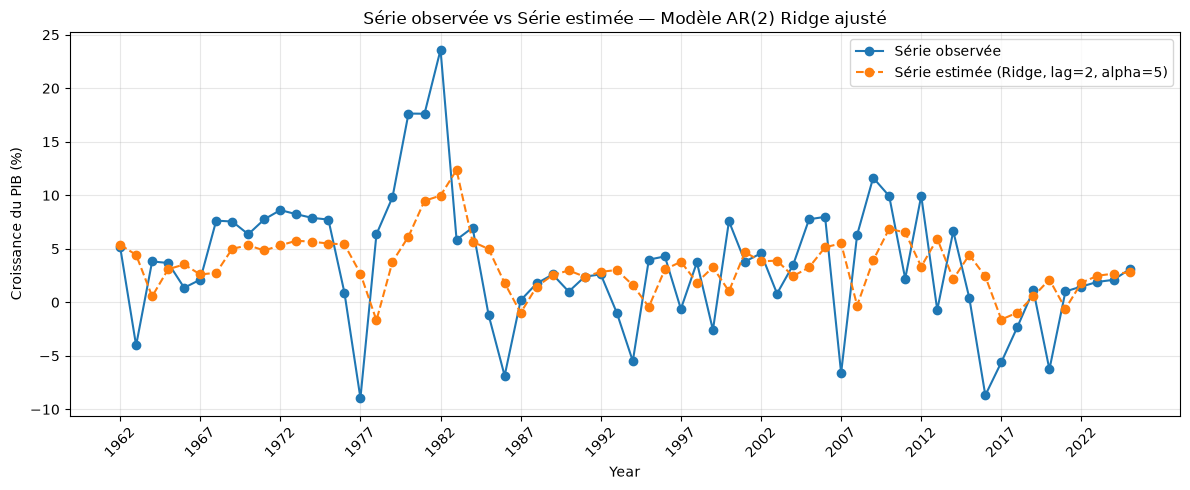

In [57]:
annees_best = df_best["Year"].astype(int)
y_estime_best = modele_ar_best.predict(X_best)

plt.figure(figsize=(12, 5))
plt.plot(
    annees_best,
    df_best["Croissance_PIB"],
    marker="o",
    label="Série observée",
)
plt.plot(
    annees_best,
    y_estime_best,
    marker="o",
    linestyle="--",
    label="Série estimée (Ridge, lag=2, alpha=5)",
)

plt.xticks(range(annees_best.min(), annees_best.max() + 1, 5), rotation=45)
plt.title("Série observée vs Série estimée — Modèle AR(2) Ridge ajusté")
plt.xlabel("Year")
plt.ylabel("Croissance du PIB (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()